# 04 — Visualização de dados

Etapa 4 do enunciado. Os dados vêm do banco `banco/nice_rooms.db` criado no notebook 03 (Pandas + SQL, Aula 14). Para cada gráfico apresento:

- **a pergunta** que ele responde;
- **por que este tipo de gráfico** (Aula 01 e aulas específicas);
- **o que o leitor deve concluir**, em uma ou duas frases.

Práticas da Aula 10 aplicadas a todos os gráficos: o **título informa a conclusão**, os eixos têm unidades, a **paleta é consistente** (cada *tier* tem sempre a mesma cor; azul = bom, vermelho = ruim, cinza = neutro) e não há elementos decorativos.

In [1]:
import re
import sqlite3
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from wordcloud import STOPWORDS, WordCloud

from nice_rooms import (ARQUIVO_BANCO, CORES_TIER, COR_BOM, COR_NEUTRO, COR_RUIM, COR_TEXTO,
                        ORDEM_TIER, PASTA_FIGURAS, estilo_graficos)

estilo_graficos()
pio.renderers.default = "plotly_mimetype+notebook_connected"
PASTA_FIGURAS.mkdir(exist_ok=True)
conexao = sqlite3.connect(ARQUIVO_BANCO)


def sql(consulta: str) -> pd.DataFrame:
    return pd.read_sql(consulta, conexao)


def salvar(fig, nome: str) -> None:
    """Salva a figura em PNG (usada no relatório executivo)."""
    fig.savefig(PASTA_FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

---
## Gráfico 1 — Como os tiers se comparam em ocupação, diária e RevPAR?

**Tipo:** três gráficos de **barras horizontais** lado a lado (*small multiples*, Aula 06). Barras são a melhor forma de comparar magnitudes entre categorias. As três medidas têm unidades diferentes (% e USD), então cada uma ganha seu próprio painel em vez de um gráfico com dois eixos. Os indicadores são calculados como razão de somas (ponderados pelo tamanho do hotel), como no notebook 03.

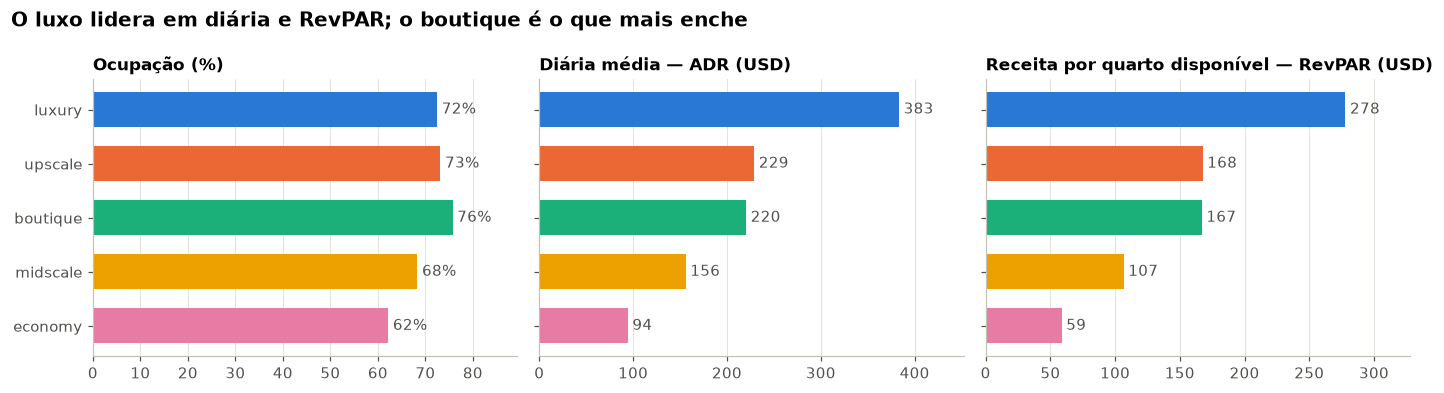

In [2]:
tiers = sql("""
SELECT h.tier,
       100.0 * SUM(d.rooms_sold) / SUM(d.rooms_available) AS ocupacao,
       SUM(d.room_revenue) / SUM(d.rooms_sold)            AS adr,
       SUM(d.room_revenue) / SUM(d.rooms_available)       AS revpar
FROM daily_market d JOIN hotels h ON h.hotel_id = d.hotel_id
GROUP BY h.tier
""").set_index("tier").reindex(ORDEM_TIER[::-1])

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
paineis = [("ocupacao", "Ocupação (%)", "{:.0f}%"), ("adr", "Diária média — ADR (USD)", "{:.0f}"),
           ("revpar", "Receita por quarto disponível — RevPAR (USD)", "{:.0f}")]
cores = [CORES_TIER[t] for t in tiers.index]
for eixo, (coluna, titulo, formato) in zip(eixos, paineis):
    barras = eixo.barh(tiers.index, tiers[coluna], color=cores, height=0.65)
    eixo.bar_label(barras, labels=[formato.format(v) for v in tiers[coluna]], padding=3, color=COR_TEXTO)
    eixo.set_title(titulo, fontsize=11)
    eixo.grid(axis="y", visible=False)
    eixo.set_xlim(0, tiers[coluna].max() * 1.18)
fig.suptitle("O luxo lidera em diária e RevPAR; o boutique é o que mais enche", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
salvar(fig, "01_tiers")
plt.show()

**Conclusão:** a diferença entre *tiers* está quase toda na **diária**: o luxo cobra 4× o econômico, enquanto a ocupação varia só de ~62% a ~76%. Por isso o RevPAR segue a ordem de preço, e o *boutique* (o mais cheio) empata com o *upscale*.

---
## Gráfico 2 — Como ocupação e diária evoluem nos dois anos? Os eventos aparecem?

**Tipo:** **linhas** (Aula 07), a forma natural para uma série temporal, em **dois painéis empilhados com o mesmo eixo de tempo**. Ocupação (%) e diária (USD) têm escalas diferentes, e um gráfico com dois eixos verticais induziria comparações falsas. As **semanas com evento** aparecem como faixas sombreadas, com o nome do evento no primeiro ano.

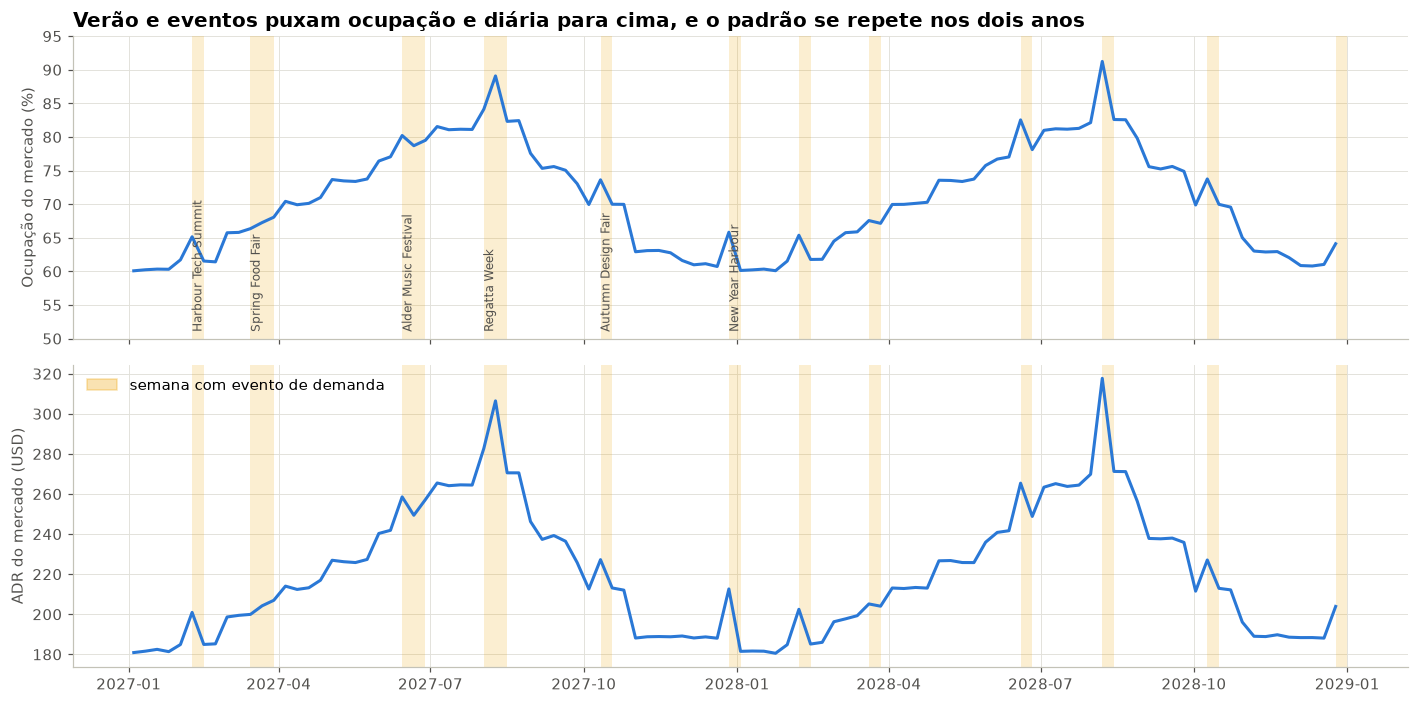

In [3]:
semanas = sql("""
SELECT week_start,
       100.0 * SUM(rooms_sold) / SUM(available_rooms) AS ocupacao,
       SUM(room_revenue) / SUM(rooms_sold)            AS adr,
       MAX(demand_event)                               AS evento
FROM weekly_performance
GROUP BY week_start ORDER BY week_start
""")
semanas["week_start"] = pd.to_datetime(semanas["week_start"])

fig, (eixo_occ, eixo_adr) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
eixo_occ.plot(semanas["week_start"], semanas["ocupacao"], color=COR_BOM, linewidth=2)
eixo_adr.plot(semanas["week_start"], semanas["adr"], color=COR_BOM, linewidth=2)

ja_rotulados = set()
for _, linha in semanas[semanas["evento"] != ""].iterrows():
    for eixo in (eixo_occ, eixo_adr):
        eixo.axvspan(linha["week_start"], linha["week_start"] + pd.Timedelta(days=7), color="#eda100", alpha=0.18, lw=0)
    if linha["evento"] not in ja_rotulados and linha["week_start"].year == 2027:
        eixo_occ.text(linha["week_start"] + pd.Timedelta(days=3.5), 51, linha["evento"], rotation=90,
                      fontsize=8, color=COR_TEXTO, ha="center", va="bottom")
        ja_rotulados.add(linha["evento"])

eixo_occ.set_ylabel("Ocupação do mercado (%)")
eixo_adr.set_ylabel("ADR do mercado (USD)")
eixo_occ.set_ylim(50, 95)
eixo_occ.set_title("Verão e eventos puxam ocupação e diária para cima, e o padrão se repete nos dois anos")
eixo_adr.legend(handles=[Patch(color="#eda100", alpha=0.3, label="semana com evento de demanda")], loc="upper left")
plt.tight_layout()
salvar(fig, "02_evolucao")
plt.show()

**Conclusão:** a sazonalidade é forte e **igual em 2027 e 2028**, com pico em julho/agosto e vale no inverno. Os eventos aparecem como **picos isolados** sobre a curva sazonal, mais visíveis fora do verão (Harbour Tech Summit, Autumn Design Fair, New Year Harbour). Ocupação e diária sobem juntas.

---
## Gráfico 3 — Mapa de posicionamento: quem cobra caro e enche?

**Tipo:** **dispersão com quadrantes** (Aula 08). Cada hotel é um ponto:

- eixo X = **ARI**, o índice de preço (ADR do hotel ÷ ADR dos concorrentes × 100);
- eixo Y = **MPI**, o índice de ocupação (ocupação do hotel ÷ ocupação dos concorrentes × 100);
- tamanho do ponto = número de quartos, e cor = *tier*.

**Linha de referência: 100 nos dois eixos.** O README define 100 como **paridade com o próprio comp set**: o hotel cobra e enche exatamente como seus concorrentes diretos. Usar a média do mercado inteiro (luxo + econômico misturados) seria errado, porque cada hotel compete só com seu *tier*. Os nomes dos hotéis são escritos ao lado dos pontos, para que a identificação não dependa só da cor.

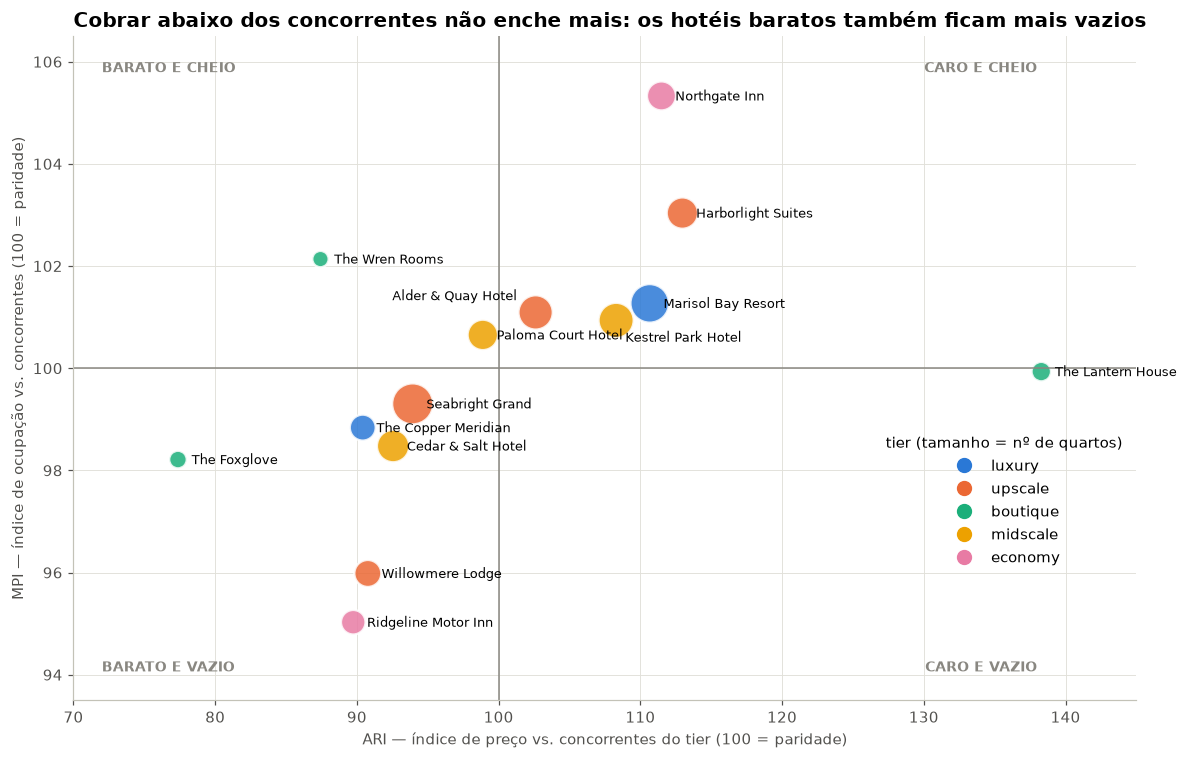

,name,tier,ari,mpi,rgi
10,The Foxglove,boutique,77.4,98.2,76.0
11,Ridgeline Motor Inn,economy,89.7,95.0,85.3
13,Willowmere Lodge,upscale,90.8,96.0,87.1
6,The Wren Rooms,boutique,87.4,102.1,89.3
4,The Copper Meridian,luxury,90.4,98.8,89.4
8,Cedar & Salt Hotel,midscale,92.6,98.5,91.2
5,Seabright Grand,upscale,93.9,99.3,93.3
12,Paloma Court Hotel,midscale,98.9,100.7,99.6
0,Alder & Quay Hotel,upscale,102.6,101.1,103.8
9,Kestrel Park Hotel,midscale,108.3,100.9,109.3


In [4]:
posicao = sql("""
SELECT h.hotel_id, h.name, h.tier, h.rooms,
       AVG(d.ari) AS ari, AVG(d.mpi) AS mpi, AVG(d.rgi) AS rgi
FROM daily_market d JOIN hotels h ON h.hotel_id = d.hotel_id
GROUP BY h.hotel_id
""")

fig, eixo = plt.subplots(figsize=(11, 7))
for tier in ORDEM_TIER:
    pedaco = posicao[posicao["tier"] == tier]
    eixo.scatter(pedaco["ari"], pedaco["mpi"], s=pedaco["rooms"] * 3, color=CORES_TIER[tier], alpha=0.85,
                 edgecolor="white", linewidth=1.5, label=tier)
deslocamento = {"Alder & Quay Hotel": (-12, 8, "right"), "Kestrel Park Hotel": (6, -14, "left")}
for _, h in posicao.iterrows():
    dx, dy, alinhamento = deslocamento.get(h["name"], (9, -3, "left"))
    eixo.annotate(h["name"], (h["ari"], h["mpi"]), xytext=(dx, dy), textcoords="offset points",
                  fontsize=8.5, ha=alinhamento)

eixo.axvline(100, color="#898781", linewidth=1)
eixo.axhline(100, color="#898781", linewidth=1)
eixo.set_xlim(70, 145)
eixo.set_ylim(93.5, 106.5)
rotulos = {(138, 106): "CARO E CHEIO", (138, 94): "CARO E VAZIO", (72, 106): "BARATO E CHEIO", (72, 94): "BARATO E VAZIO"}
for (x, y), texto in rotulos.items():
    eixo.text(x, y, texto, fontsize=9, color="#898781", fontweight="bold", ha="left" if x < 100 else "right",
              va="top" if y > 100 else "bottom")
eixo.set_xlabel("ARI — índice de preço vs. concorrentes do tier (100 = paridade)")
eixo.set_ylabel("MPI — índice de ocupação vs. concorrentes (100 = paridade)")
eixo.set_title("Cobrar abaixo dos concorrentes não enche mais: os hotéis baratos também ficam mais vazios")
marcadores = [Line2D([], [], marker="o", linestyle="", markersize=9, color=CORES_TIER[t], label=t) for t in ORDEM_TIER]
eixo.legend(handles=marcadores, title="tier (tamanho = nº de quartos)", loc="center right",
            bbox_to_anchor=(1.0, 0.3))
plt.tight_layout()
salvar(fig, "03_posicionamento")
plt.show()

posicao.sort_values("rgi").round(1)[["name", "tier", "ari", "mpi", "rgi"]]

**Conclusão:** cinco hotéis **cobram caro e enchem** (Harborlight Suites, Northgate Inn, Marisol Bay, Kestrel Park, Alder & Quay). The Lantern House cobra 38% acima dos pares e mantém ocupação de paridade. O achado principal é o quadrante **"barato e vazio"**: The Foxglove, Ridgeline, Willowmere, Cedar & Salt, The Copper Meridian e Seabright cobram **menos** que os concorrentes e **também** vendem menos. O desconto não está comprando volume, e todos eles têm RGI abaixo de 100. Só The Wren Rooms (e, por pouco, Paloma Court) cobra menos e enche um pouco mais que os pares.

---
## Gráfico 4 — Quanto o preço praticado se afasta da diária MARS?

**Tipo:** **box plot** por hotel. É o gráfico adequado para comparar **distribuições** entre muitos grupos, porque mostra mediana, dispersão e valores extremos de 728 noites por hotel em pouco espaço. Os hotéis são agrupados por *tier* e a **faixa de ±6%** (a faixa "utilizável" da MARS, segundo o README) aparece sombreada.

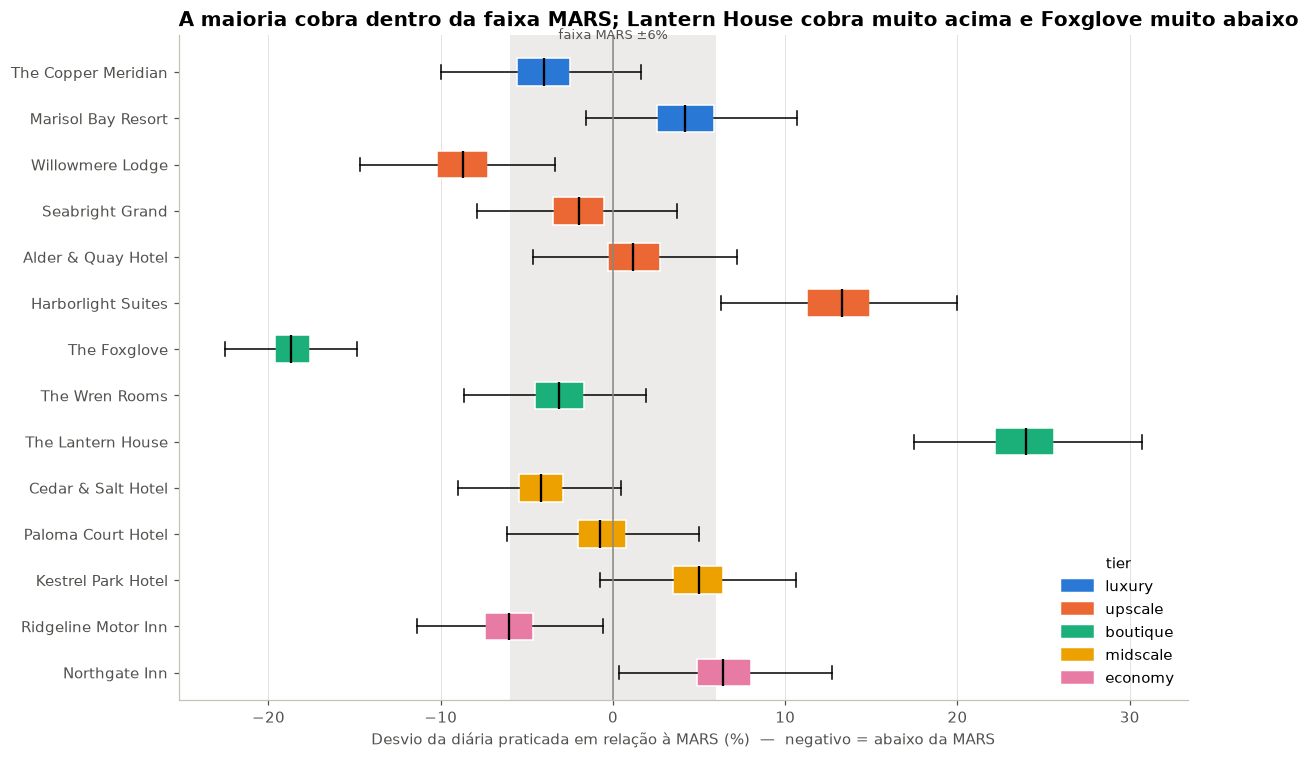

In [5]:
desvio = sql("""
SELECT h.name, h.tier, d.rate_gap_pct
FROM daily_market d JOIN hotels h ON h.hotel_id = d.hotel_id
""")
ordem = (desvio.groupby(["tier", "name"])["rate_gap_pct"].median().reset_index()
         .assign(ordem_tier=lambda x: x["tier"].map({t: i for i, t in enumerate(ORDEM_TIER)}))
         .sort_values(["ordem_tier", "rate_gap_pct"]))

fig, eixo = plt.subplots(figsize=(11, 7))
dados_box = [desvio.loc[desvio["name"] == n, "rate_gap_pct"] for n in ordem["name"]]
caixas = eixo.boxplot(dados_box, orientation="horizontal", patch_artist=True, widths=0.6, showfliers=False,
                      medianprops={"color": "black", "linewidth": 1.5})
for caixa, tier in zip(caixas["boxes"], ordem["tier"]):
    caixa.set_facecolor(CORES_TIER[tier])
    caixa.set_edgecolor("white")
eixo.set_yticks(range(1, len(ordem) + 1), ordem["name"])
eixo.axvspan(-6, 6, color=COR_NEUTRO, alpha=0.25, lw=0)
eixo.axvline(0, color="#898781", linewidth=1)
eixo.invert_yaxis()
eixo.text(0, 0.35, "faixa MARS ±6%", ha="center", va="bottom", fontsize=8.5, color=COR_TEXTO)
eixo.set_ylim(len(ordem) + 0.6, 0.2)
eixo.set_xlabel("Desvio da diária praticada em relação à MARS (%)  —  negativo = abaixo da MARS")
eixo.set_title("A maioria cobra dentro da faixa MARS; Lantern House cobra muito acima e Foxglove muito abaixo")
eixo.grid(axis="y", visible=False)
eixo.legend(handles=[Patch(color=CORES_TIER[t], label=t) for t in ORDEM_TIER], loc="lower right", title="tier")
plt.tight_layout()
salvar(fig, "04_desvio_mars")
plt.show()

**Conclusão:** oito dos 14 hotéis têm a mediana dentro da faixa de ±6%, e Northgate (+6%) e Ridgeline (−6%) estão no limite. Os desvios **sistemáticos** são The Lantern House (~+24%, sempre acima), Harborlight Suites (~+13%) e, no sentido oposto, **The Foxglove (~−19%)** e Willowmere Lodge (~−9%). As caixas são estreitas: o desvio é uma **política de preço constante**, não um acaso de algumas noites.

---
## Gráfico 5 — Como se distribuem os cenários das avaliações?

**Por que não um gráfico de pizza?** A Aula 09 recomenda pizza só para **poucas fatias** (até ~5) que somam um todo e têm tamanhos bem diferentes. Aqui são **11 cenários** com participações parecidas (4% a 15%), e o olho humano compara mal ângulos tão próximos. Por isso uso **barras horizontais ordenadas** (Aula 06), com rótulos de porcentagem e cor pelo sentimento esperado do cenário.

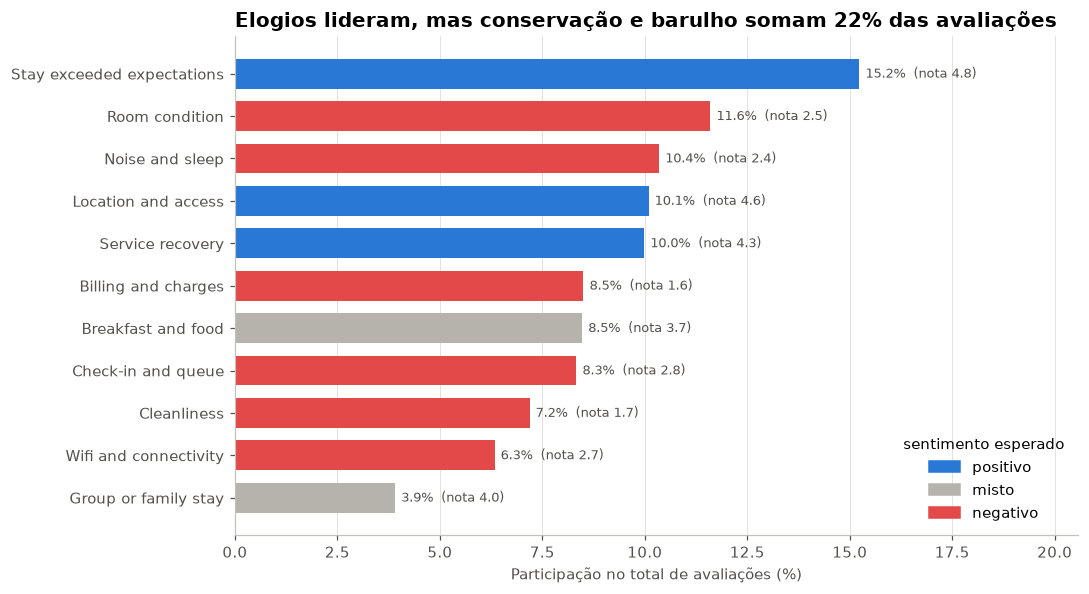

In [6]:
cenarios = sql("""
SELECT s.label, s.expected_sentiment, COUNT(*) AS avaliacoes, AVG(r.rating) AS nota
FROM reviews r JOIN review_scenarios s ON s.scenario_id = r.scenario_id
GROUP BY s.scenario_id ORDER BY avaliacoes
""")
cenarios["pct"] = cenarios["avaliacoes"] / cenarios["avaliacoes"].sum() * 100
cor_sentimento = {"positive": COR_BOM, "mixed": COR_NEUTRO, "negative": COR_RUIM}

fig, eixo = plt.subplots(figsize=(10, 5.5))
barras = eixo.barh(cenarios["label"], cenarios["pct"], color=cenarios["expected_sentiment"].map(cor_sentimento), height=0.7)
eixo.bar_label(barras, labels=[f"{p:.1f}%  (nota {n:.1f})" for p, n in zip(cenarios["pct"], cenarios["nota"])],
               padding=4, fontsize=8.5, color=COR_TEXTO)
eixo.set_xlim(0, cenarios["pct"].max() * 1.35)
eixo.set_xlabel("Participação no total de avaliações (%)")
eixo.grid(axis="y", visible=False)
eixo.set_title("Elogios lideram, mas conservação e barulho somam 22% das avaliações")
eixo.legend(handles=[Patch(color=c, label={"positive": "positivo", "mixed": "misto", "negative": "negativo"}[s])
                     for s, c in cor_sentimento.items()], title="sentimento esperado", loc="lower right")
plt.tight_layout()
salvar(fig, "05_cenarios")
plt.show()

**Conclusão:** "Stay exceeded expectations" é o cenário mais comum (15%), mas os dois problemas seguintes, **conservação do quarto** e **barulho**, juntos já superam os elogios. Os cenários negativos e mistos (vermelho e cinza) são maioria, o que explica os 55,8% de avaliações com 3 estrelas ou menos.

---
## Gráfico 6 — Fluxo das avaliações: do cenário à faixa de nota

**Tipo:** **Sankey** (Aula 12), feito para mostrar como um conjunto de categorias se **distribui** em outro. A largura de cada fluxo é o número de avaliações. À esquerda ficam os 11 cenários, à direita as faixas de nota (1–2, 3, 4–5 estrelas). O gráfico é interativo: passe o mouse sobre um fluxo para ver a contagem.

In [7]:
fluxo = sql("""
SELECT s.label AS origem,
       CASE WHEN r.rating <= 2 THEN '1–2 estrelas' WHEN r.rating = 3 THEN '3 estrelas' ELSE '4–5 estrelas' END AS destino,
       COUNT(*) AS avaliacoes
FROM reviews r JOIN review_scenarios s ON s.scenario_id = r.scenario_id
GROUP BY origem, destino
""")
ordem_origem = cenarios.sort_values("nota", ascending=False)["label"].tolist()
destinos = ["4–5 estrelas", "3 estrelas", "1–2 estrelas"]
nos = ordem_origem + destinos
indice = {nome: i for i, nome in enumerate(nos)}
cor_destino = {"4–5 estrelas": "rgba(42,120,214,0.45)", "3 estrelas": "rgba(181,179,171,0.55)",
               "1–2 estrelas": "rgba(227,73,72,0.45)"}

sankey = go.Figure(go.Sankey(
    arrangement="snap",
    node={"label": nos, "pad": 12, "thickness": 16,
          "color": ["#898781"] * len(ordem_origem) + [COR_BOM, COR_NEUTRO, COR_RUIM]},
    link={"source": fluxo["origem"].map(indice), "target": fluxo["destino"].map(indice),
          "value": fluxo["avaliacoes"], "color": fluxo["destino"].map(cor_destino),
          "hovertemplate": "%{source.label} → %{target.label}<br>%{value} avaliações<extra></extra>"},
))
sankey.update_layout(title="Cobrança, limpeza, conservação e barulho geram 82% das notas 1–2",
                     font_size=12, height=560, margin={"l": 10, "r": 10, "t": 60, "b": 10})
sankey.write_html(PASTA_FIGURAS / "06_sankey.html", include_plotlyjs="cdn")
sankey.show()

In [8]:
tabela_fluxo = fluxo.pivot(index="origem", columns="destino", values="avaliacoes").fillna(0).astype(int)
participacao_1_2 = (tabela_fluxo["1–2 estrelas"] / tabela_fluxo["1–2 estrelas"].sum() * 100).sort_values(ascending=False)
print("De onde vêm as avaliações de 1–2 estrelas (%):")
print(participacao_1_2.round(1).to_string())

De onde vêm as avaliações de 1–2 estrelas (%):
origem
Billing and charges           25.8
Cleanliness                   20.8
Room condition                18.4
Noise and sleep               17.4
Check-in and queue             9.4
Wifi and connectivity          8.3
Breakfast and food             0.0
Group or family stay           0.0
Location and access            0.0
Service recovery               0.0
Stay exceeded expectations     0.0


**Conclusão:** as notas 1–2 vêm de seis cenários, e **quatro deles** (cobrança, limpeza, conservação do quarto e barulho) somam **82%**. Check-in e wifi completam o restante. Os cenários positivos fluem quase todos para 4–5 estrelas. Para reduzir notas ruins, a associação deve atacar essas quatro causas, e as ações de recuperação de cada uma já estão documentadas.

---
## Gráfico 7 — O que dizem as avaliações positivas e as negativas?

**Tipo:** **nuvens de palavras** lado a lado (Aula 13). Uma para avaliações de 4–5 estrelas (azul) e outra para 1–2 estrelas (vermelho).

Uma nuvem "crua" é dominada por palavras genéricas e pouco informativas. Na primeira versão, "rate", "made" e "good" eram as maiores. Por isso:

1. passo tudo para minúsculas e removo *stopwords* do inglês e palavras de enchimento;
2. mantenho em cada nuvem só as palavras **distintivas**: as que são, proporcionalmente, pelo menos **3 vezes mais frequentes** naquele grupo do que no outro;
3. o tamanho da palavra é a frequência dela no grupo.

Limitação conhecida: a nuvem mostra frequência, não contexto. Além disso, os textos são **sintéticos**, montados a partir de frases-modelo, por isso o vocabulário é repetitivo.

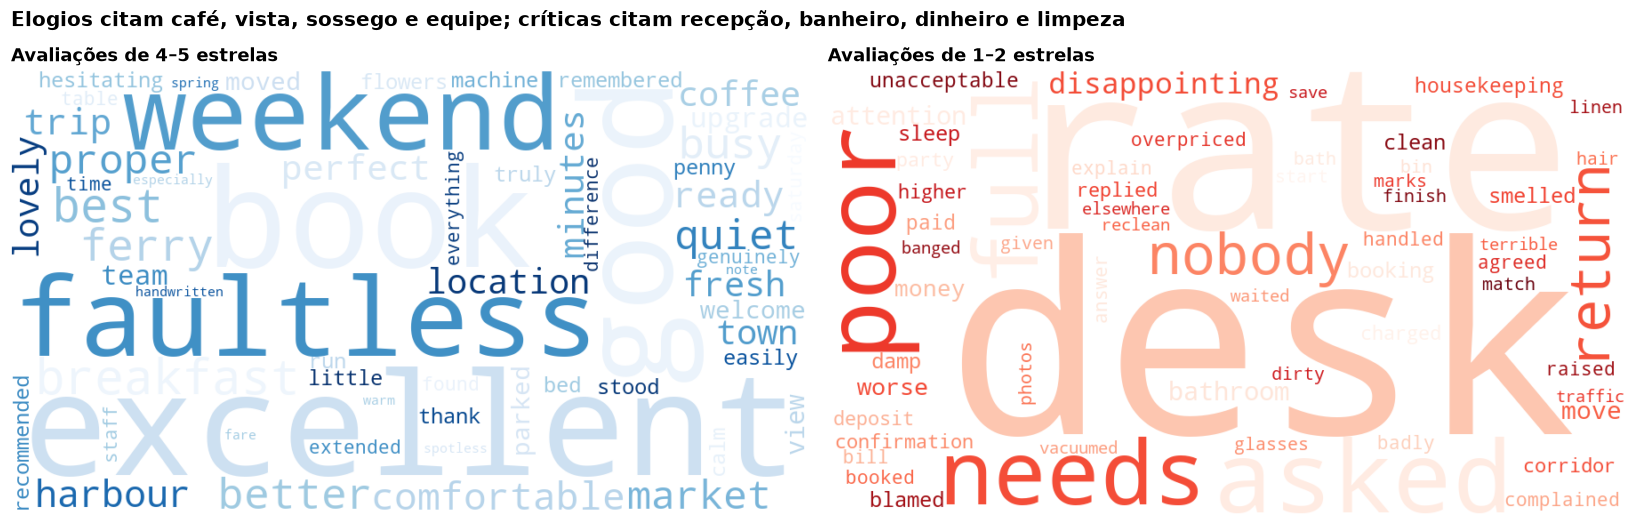

Mais frequentes (positivas): ['excellent', 'book', 'good', 'faultless', 'weekend', 'breakfast', 'best', 'ferry', 'busy', 'better', 'proper', 'quiet', 'market', 'comfortable', 'harbour']
Mais frequentes (negativas): ['desk', 'rate', 'asked', 'poor', 'needs', 'full', 'nobody', 'return', 'disappointing', 'bathroom', 'attention', 'move', 'worse', 'money', 'booking']


In [9]:
textos = sql("SELECT rating, title || ' ' || text AS texto FROM reviews")
palavras_vazias = STOPWORDS | {"made", "needed", "find", "really", "will", "already", "without", "exactly",
                              "first", "ask", "still", "come", "told", "much", "far", "work", "close", "site",
                              "well", "old", "every", "part", "things", "next", "day", "back", "even", "got"}


def contar_palavras(serie: pd.Series) -> Counter:
    """Conta as palavras (minúsculas, 3+ letras, sem stopwords) de um conjunto de textos."""
    return Counter(p for texto in serie for p in re.findall(r"[a-z]+", texto.lower())
                   if len(p) > 2 and p not in palavras_vazias)


def distintivas(grupo: Counter, outro: Counter, razao_minima: float = 3, minimo: int = 30) -> dict:
    """Palavras proporcionalmente muito mais frequentes no grupo do que no outro."""
    total_g, total_o = sum(grupo.values()), sum(outro.values())
    return {p: n for p, n in grupo.items()
            if n >= minimo and ((n + 1) / total_g) / ((outro[p] + 1) / total_o) >= razao_minima}


cont_pos = contar_palavras(textos.loc[textos["rating"] >= 4, "texto"])
cont_neg = contar_palavras(textos.loc[textos["rating"] <= 2, "texto"])
freq_pos, freq_neg = distintivas(cont_pos, cont_neg), distintivas(cont_neg, cont_pos)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))
for eixo, (titulo, frequencias, cor) in zip(eixos, [("Avaliações de 4–5 estrelas", freq_pos, "Blues"),
                                                    ("Avaliações de 1–2 estrelas", freq_neg, "Reds")]):
    nuvem = WordCloud(width=900, height=500, background_color="white", colormap=cor, max_words=60,
                      min_font_size=9, random_state=7).generate_from_frequencies(frequencias)
    eixo.imshow(nuvem, interpolation="bilinear")
    eixo.set_title(titulo, fontsize=12)
    eixo.axis("off")
fig.suptitle("Elogios citam café, vista, sossego e equipe; críticas citam recepção, banheiro, dinheiro e limpeza",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
salvar(fig, "07_nuvens")
plt.show()

print("Mais frequentes (positivas):", [p for p, _ in Counter(freq_pos).most_common(15)])
print("Mais frequentes (negativas):", [p for p, _ in Counter(freq_neg).most_common(15)])

**Conclusão:** as avaliações positivas falam da **experiência**: café da manhã, vista do porto, balsa, localização, sossego, conforto, equipe e *upgrade*. As negativas falam de **falhas operacionais e de dinheiro**: a recepção (*desk*) e o "ninguém" (*nobody*) que não resolveu, banheiro, umidade e cheiro, limpeza e cobranças (*rate*, *money*, *charged*, *deposit*). É a mesma história do Sankey, agora contada pelas palavras dos hóspedes.

---
## Gráfico 8 — As decisões de preço funcionam? (resultado da semana seguinte)

**Tipo:** **barras 100% empilhadas** (Aula 06): para cada ação (aumentar, manter, reduzir), a proporção de semanas seguintes melhores, iguais ou piores. Barras empilhadas em 100% comparam **composições** entre poucos grupos. As cores seguem a escala divergente (azul = melhor, cinza = igual, vermelho = pior).

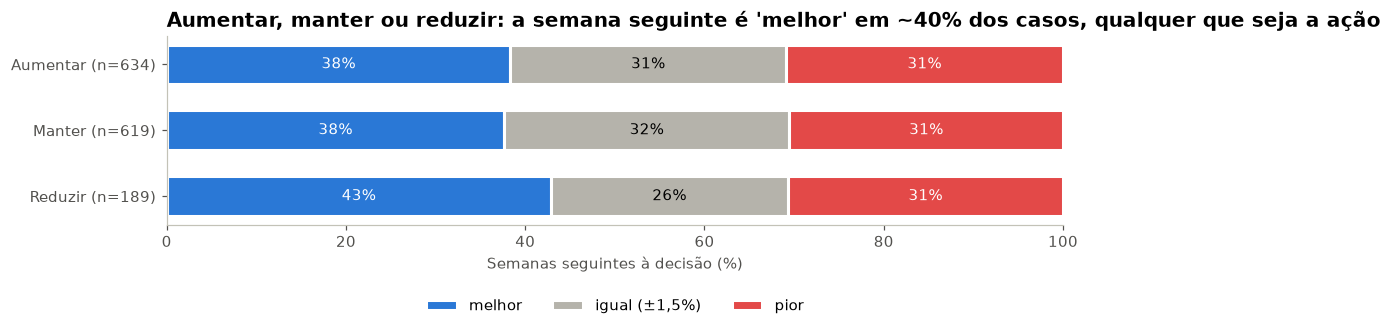

In [10]:
resultado = sql("""
SELECT action, outcome, COUNT(*) AS n FROM rate_decisions GROUP BY action, outcome
""").pivot(index="action", columns="outcome", values="n").reindex(["lower", "hold", "raise"])
resultado_pct = resultado.div(resultado.sum(axis=1), axis=0)[["better", "in line", "worse"]] * 100
rotulos_acao = {"raise": "Aumentar", "hold": "Manter", "lower": "Reduzir"}
rotulos_res = {"better": "melhor", "in line": "igual (±1,5%)", "worse": "pior"}

fig, eixo = plt.subplots(figsize=(10, 3.4))
esquerda = np.zeros(len(resultado_pct))
for coluna, cor in zip(["better", "in line", "worse"], [COR_BOM, COR_NEUTRO, COR_RUIM]):
    barras = eixo.barh([f"{rotulos_acao[a]} (n={resultado.loc[a].sum()})" for a in resultado_pct.index],
                       resultado_pct[coluna], left=esquerda, color=cor, label=rotulos_res[coluna],
                       height=0.6, edgecolor="white", linewidth=2)
    eixo.bar_label(barras, labels=[f"{v:.0f}%" for v in resultado_pct[coluna]], label_type="center",
                   color="white" if coluna != "in line" else "black", fontsize=10)
    esquerda += resultado_pct[coluna].to_numpy()
eixo.set_xlim(0, 100)
eixo.set_xlabel("Semanas seguintes à decisão (%)")
eixo.grid(visible=False)
eixo.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
eixo.set_title("Aumentar, manter ou reduzir: a semana seguinte é 'melhor' em ~40% dos casos, qualquer que seja a ação")
plt.tight_layout()
salvar(fig, "08_decisoes")
plt.show()

**Conclusão:** as três ações produzem **praticamente a mesma distribuição** de resultados. O indicador "semana seguinte melhor" **não separa** boas e más decisões, porque a semana seguinte varia por sazonalidade e eventos. Avaliar o efeito real do preço exigiria um grupo de comparação (contrafactual), que o dataset não tem.

---
## Gráfico 9 (interativo) — Semanas com nota melhor têm RevPAR maior?

**Tipo:** **dispersão interativa em Plotly** (Aulas 15 e 16). Cada ponto é uma semana de um hotel. O *tooltip* mostra hotel, semana, nota média, número de avaliações e RevPAR. Clique na legenda para isolar um *tier*. O gráfico visualiza o achado da Etapa 2 sobre **correlação espúria**.

In [11]:
semanas_nota = sql("""
SELECT w.week_start, h.name AS hotel, h.tier, w.mean_rating, w.review_count, w.revpar
FROM weekly_performance w JOIN hotels h ON h.hotel_id = w.hotel_id
WHERE w.mean_rating IS NOT NULL
""")
interativo = px.scatter(
    semanas_nota, x="mean_rating", y="revpar", color="tier",
    category_orders={"tier": ORDEM_TIER}, color_discrete_map=CORES_TIER, opacity=0.6,
    hover_name="hotel",
    hover_data={"week_start": True, "mean_rating": ":.2f", "review_count": True, "revpar": ":.0f", "tier": False},
    labels={"mean_rating": "Nota média da semana (estrelas)", "revpar": "RevPAR da semana (USD)",
            "week_start": "Semana", "review_count": "Avaliações", "tier": "Tier"},
    title="Dentro de cada tier, a nota da semana não mexe no RevPAR: as faixas são horizontais",
)
interativo.update_traces(marker={"size": 7, "line": {"width": 0.5, "color": "white"}})
interativo.update_layout(template="simple_white", height=520, legend_title_text="Tier (clique para filtrar)")
interativo.write_html(PASTA_FIGURAS / "09_nota_revpar.html", include_plotlyjs="cdn")
interativo.show()

In [12]:
r_geral = semanas_nota["mean_rating"].corr(semanas_nota["revpar"])
r_tier = semanas_nota.groupby("tier").apply(lambda g: g["mean_rating"].corr(g["revpar"])).reindex(ORDEM_TIER)
print(f"Correlação geral: {r_geral:.2f}")
print("Dentro de cada tier:")
print(r_tier.round(2).to_string())

Correlação geral: 0.22
Dentro de cada tier:
tier
luxury     -0.02
upscale     0.03
boutique   -0.03
midscale   -0.06
economy     0.03


**Conclusão:** cada *tier* forma uma **faixa horizontal**: a nota da semana varia muito (de 1 a 5) sem que o RevPAR acompanhe, com correlação perto de zero dentro de cada tier. A correlação positiva do mercado inteiro (~0,2) vem apenas de as faixas estarem em alturas diferentes: o luxo tem RevPAR mais alto **e** notas um pouco melhores.

---
## Resumo das visualizações

| # | Pergunta | Tipo | Principal conclusão |
|---|---|---|---|
| 1 | Tiers em ocupação, ADR e RevPAR | barras (small multiples) | A diferença está no preço, não na ocupação |
| 2 | Evolução em dois anos | linhas empilhadas + faixas de evento | Sazonalidade forte e repetida; eventos são picos isolados |
| 3 | Posicionamento | dispersão com quadrantes | Desconto não compra ocupação: os baratos também ficam vazios |
| 4 | Desvio da MARS | box plot | Desvios são políticas constantes (Lantern House +24%, Foxglove −19%) |
| 5 | Cenários | barras ordenadas (não pizza) | Conservação + barulho superam os elogios |
| 6 | Cenário → nota | Sankey | 4 causas geram 82% das notas 1–2 |
| 7 | Texto positivo × negativo | nuvens de palavras | Elogio = pessoas; crítica = operação |
| 8 | Decisões de preço | barras 100% empilhadas | Resultado igual para as três ações; não prova causa |
| 9 | Nota × RevPAR (interativo) | dispersão Plotly | Correlação espúria: some dentro do tier |

In [13]:
conexao.close()
print("Figuras salvas em:", sorted(p.name for p in PASTA_FIGURAS.iterdir()))

Figuras salvas em: ['01_tiers.png', '02_evolucao.png', '03_posicionamento.png', '04_desvio_mars.png', '05_cenarios.png', '06_sankey.html', '07_nuvens.png', '08_decisoes.png', '09_nota_revpar.html']
